# Justificación de países de interés: ¿dónde hay más hotspots de incendio activo?

**Proyecto:** NASA Space Apps · Burning Activity Calendar  **Área:** [ANALÍTICA] [DATOS]

**Pregunta.** ¿Son República Democrática del Congo, Brasil, Angola, Australia y Rusia los países con más hotspots en el archivo histórico de FIRMS? México se añade como caso de interés propio, no porque deba salir en el ranking.

**Datos.** Tablas resumen `tablas/summary_country_month.csv.gz` y `tablas/summary_grid1deg_year.csv.gz` (carpeta `analisis/01_paises/tablas/`), generadas por `summarize_firms.py` a partir de los 48 zips anuales por país de FIRMS (MODIS 2000–2025, VIIRS S-NPP 2012–2025, VIIRS NOAA-20 2018–2025). Fuente: <https://firms.modaps.eosdis.nasa.gov/country/>.

**Método.** (1) Verificar integridad de las tablas. (2) Rankear países por número de hotspots en cada instrumento. (3) Comprobar si los cinco países son el top-5 de forma programática, por conteo y por FRP. (4) Repetir en un periodo común a los tres sensores. (5) Revisar estabilidad año por año. (6) Medir concentración y ver el mapa. Si el resultado no fuera robusto, el notebook lo mostraría.

**Advertencia de lectura.** Un hotspot es una detección de píxel, no una cantidad de área quemada. Los conteos MODIS (1 km) y VIIRS (375 m) **no son comparables entre sí**; por eso todo se compara *dentro* de cada instrumento.

## 0. Configuración

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch

def find_derived():
    # Las tablas viven junto al notebook: Data/analisis/01_paises/tablas/
    p = Path.cwd().resolve()
    for d in [p, p / "analisis" / "01_paises", *p.parents]:
        if (d / "tablas" / "summary_country_month.csv.gz").exists():
            return d / "tablas"
    raise FileNotFoundError("No encuentro analisis/01_paises/tablas/. Abre el notebook desde Data/analisis/01_paises/ o desde Data/.")

DERIVED = find_derived()

TARGET = ["Democratic_Republic_of_the_Congo", "Brazil", "Angola", "Australia", "Russian_Federation"]
MEXICO = "Mexico"
INSTR = ["modis", "viirs-snpp", "viirs-jpss1"]
NAMES = {"modis": "MODIS (Terra+Aqua, 1 km)", "viirs-snpp": "VIIRS S-NPP (375 m)", "viirs-jpss1": "VIIRS NOAA-20 (375 m)"}
# años calendario completos por instrumento (MODIS arranca en nov-2000, S-NPP el 20-ene-2012, NOAA-20 en abr-2018)
FULL_YEARS = {"modis": (2001, 2025), "viirs-snpp": (2012, 2025), "viirs-jpss1": (2019, 2025)}

# colores: énfasis (azul), México (naranja), resto (gris neutro)
C_TARGET, C_MX, C_OTHER = "#2a78d6", "#eb6834", "#b9b8b2"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#cfceca", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9, "axes.grid": False,
})
pretty = lambda s: s.replace("_", " ").replace("Democratic Republic of the Congo", "RD Congo").replace("Russian Federation", "Rusia").replace("Brazil", "Brasil").replace("Mexico", "México")
print(f"Datos: {DERIVED.parent.name}/{DERIVED.name}/ ({len(list(DERIVED.glob('*')))} archivos)")

Datos: derived/ (3 archivos)


## 1. Carga y verificación de integridad

In [2]:
cm = pd.read_csv(DERIVED / "summary_country_month.csv.gz")
cm["year"] = cm["year_month"].str[:4].astype(int)

checks = pd.DataFrame({
    "filas": cm.groupby("instrument").size(),
    "países": cm.groupby("instrument").country.nunique(),
    "primer mes": cm.groupby("instrument").year_month.min(),
    "último mes": cm.groupby("instrument").year_month.max(),
    "hotspots (n)": cm.groupby("instrument").n.sum(),
    "FRP total (MW)": cm.groupby("instrument").frp_sum.sum().round(0),
}).loc[INSTR]
display(checks.style.format({"hotspots (n)": "{:,.0f}", "FRP total (MW)": "{:,.0f}"}))

# pruebas lógicas
assert cm.duplicated(["instrument", "country", "year_month"]).sum() == 0, "hay filas duplicadas"
assert (cm.n > 0).all() and (cm.n_day <= cm.n).all(), "conteos incoherentes"
print("Nulos por columna:", cm.isna().sum().to_dict())
print("Sin duplicados; n > 0 y n_day <= n en todas las filas.")

missing = [c for c in TARGET + [MEXICO] if c not in set(cm.country)]
print("Países objetivo ausentes en los datos:", missing or "ninguno")

,filas,países,primer mes,último mes,hotspots (n),FRP total (MW)
instrument,,,,,,
modis,50408,233,2000-11,2025-12,"111,424,417","4,877,869,931"
viirs-snpp,31802,236,2012-01,2025-12,"281,144,514","2,743,631,232"
viirs-jpss1,17640,234,2018-04,2025-12,"155,932,272","1,533,577,731"


Nulos por columna: {'instrument': 0, 'country': 0, 'year_month': 0, 'n': 0, 'n_day': 0, 'frp_sum': 0, 'year': 0}
Sin duplicados; n > 0 y n_day <= n en todas las filas.
Países objetivo ausentes en los datos: ninguno


Las tablas son coherentes: sin duplicados ni nulos, y los periodos coinciden con las fechas de inicio documentadas por FIRMS para cada sensor (MODIS nov-2000, S-NPP ene-2012, NOAA-20 abr-2018). Los tres instrumentos cubren unos 235 países.

## 2. Ranking de países por número de hotspots (todo el archivo)

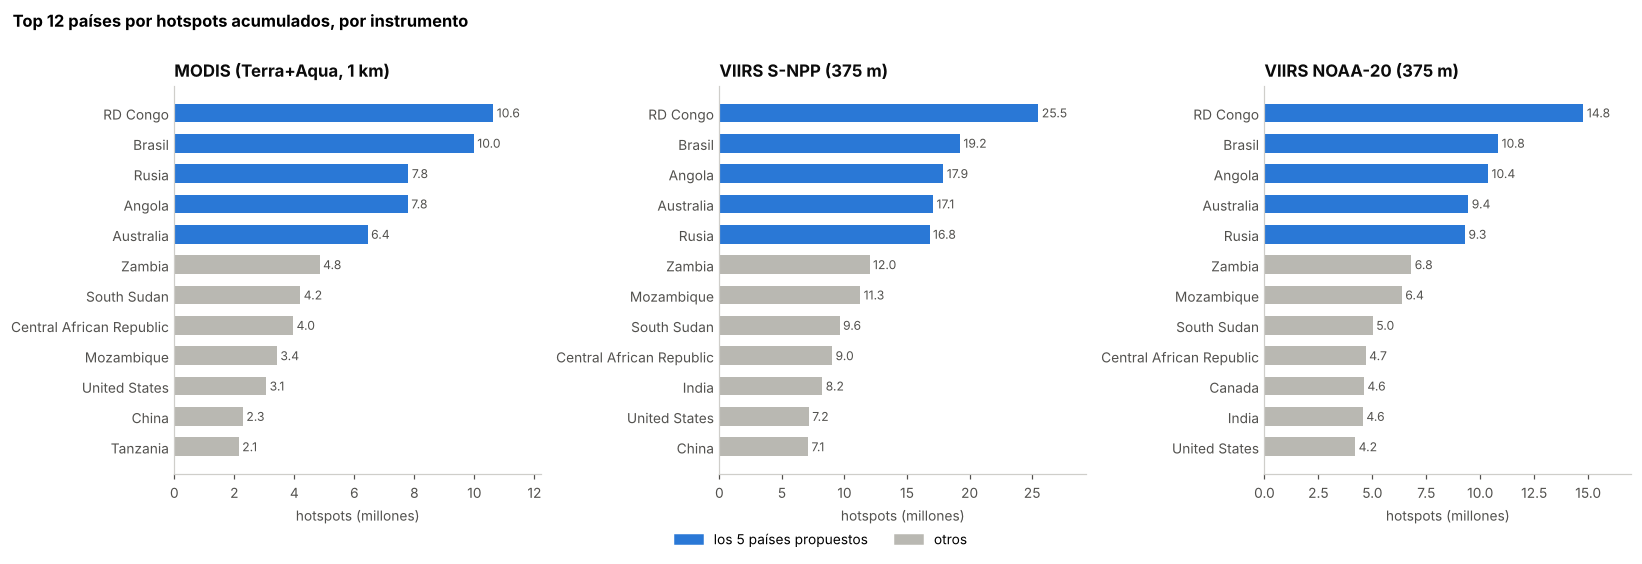

In [3]:
tot = (cm.groupby(["instrument", "country"])
         .agg(n=("n", "sum"), frp=("frp_sum", "sum")).reset_index())
tot["rank_n"] = tot.groupby("instrument").n.rank(ascending=False, method="min").astype(int)
tot["rank_frp"] = tot.groupby("instrument").frp.rank(ascending=False, method="min").astype(int)
tot["share_n"] = tot.n / tot.groupby("instrument").n.transform("sum")

TOPK = 12
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=False)
for ax, inst in zip(axes, INSTR):
    d = tot[tot.instrument == inst].nlargest(TOPK, "n").iloc[::-1]
    cols = [C_TARGET if c in TARGET else C_OTHER for c in d.country]
    ax.barh([pretty(c) for c in d.country], d.n / 1e6, color=cols, height=0.62)
    for y, v in enumerate(d.n / 1e6):
        ax.text(v, y, f" {v:.1f}", va="center", color=INK2, fontsize=8)
    ax.set_title(NAMES[inst]); ax.set_xlabel("hotspots (millones)")
    ax.set_xlim(0, d.n.max() / 1e6 * 1.15)
    ax.tick_params(axis="y", length=0)
fig.legend(handles=[Patch(color=C_TARGET, label="los 5 países propuestos"), Patch(color=C_OTHER, label="otros")],
           loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Top 12 países por hotspots acumulados, por instrumento", x=0.01, ha="left", fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

## 3. Prueba directa: ¿el top-5 es exactamente ese conjunto?

In [4]:
rows = []
for inst in INSTR:
    d = tot[tot.instrument == inst]
    for metric, label in [("n", "conteo de hotspots"), ("frp", "FRP acumulado (MW)")]:
        top5 = d.nlargest(5, metric).country.tolist()
        rows.append({"instrumento": NAMES[inst], "métrica": label,
                     "top-5 (en orden)": ", ".join(pretty(c) for c in top5),
                     "coincide con los 5": set(top5) == set(TARGET),
                     "puesto 6": pretty(d.nlargest(6, metric).country.iloc[-1])})
t3 = pd.DataFrame(rows)
display(t3)
print(f"El conjunto propuesto es exactamente el top-5 en {int(t3['coincide con los 5'].sum())} de {len(t3)} pruebas "
      "(3 instrumentos x 2 métricas).")

,instrumento,métrica,top-5 (en orden),coincide con los 5,puesto 6
0,"MODIS (Terra+Aqua, 1 km)",conteo de hotspots,"RD Congo, Brasil, Rusia, Angola, Australia",True,Zambia
1,"MODIS (Terra+Aqua, 1 km)",FRP acumulado (MW),"Brasil, Australia, RD Congo, Rusia, Angola",True,South Sudan
2,VIIRS S-NPP (375 m),conteo de hotspots,"RD Congo, Brasil, Angola, Australia, Rusia",True,Zambia
3,VIIRS S-NPP (375 m),FRP acumulado (MW),"RD Congo, Angola, Brasil, Australia, Rusia",True,Zambia
4,VIIRS NOAA-20 (375 m),conteo de hotspots,"RD Congo, Brasil, Angola, Australia, Rusia",True,Zambia
5,VIIRS NOAA-20 (375 m),FRP acumulado (MW),"RD Congo, Angola, Brasil, Australia, Rusia",True,Canada


El conjunto propuesto es exactamente el top-5 en 6 de 6 pruebas (3 instrumentos x 2 métricas).


Al pasar de un ordenamiento por conteo a uno por FRP (potencia radiativa, un proxy de intensidad), cambia el orden interno pero **no el conjunto**: los mismos cinco países ocupan los cinco primeros puestos. Ese es el punto fuerte de la justificación.

## 4. Periodo común a los tres sensores (2019–2025)

In [5]:
common = cm[cm.year.between(2019, 2025)]
rows = []
for inst in INSTR:
    d = common[common.instrument == inst].groupby("country").agg(n=("n", "sum"), frp=("frp_sum", "sum"))
    for metric, label in [("n", "conteo"), ("frp", "FRP")]:
        top5 = d[metric].nlargest(5).index.tolist()
        gap = d[metric].nlargest(6).iloc[4] / d[metric].nlargest(6).iloc[5]
        rows.append({"instrumento": NAMES[inst], "métrica": label,
                     "top-5": ", ".join(pretty(c) for c in top5),
                     "coincide": set(top5) == set(TARGET),
                     "puesto 5 / puesto 6": round(gap, 2)})
t4 = pd.DataFrame(rows); display(t4)
print(f"Periodo común 2019-2025: coincide en {int(t4['coincide'].sum())} de {len(t4)} pruebas.")
w = t4.loc[t4["puesto 5 / puesto 6"].idxmin()]
print(f"Frontera más ajustada: {w['instrumento']}, {w['métrica']} (puesto 5 / puesto 6 = {w['puesto 5 / puesto 6']}).")

,instrumento,métrica,top-5,coincide,puesto 5 / puesto 6
0,"MODIS (Terra+Aqua, 1 km)",conteo,"RD Congo, Brasil, Angola, Rusia, Australia",True,1.26
1,"MODIS (Terra+Aqua, 1 km)",FRP,"Brasil, RD Congo, Rusia, Australia, Angola",True,1.05
2,VIIRS S-NPP (375 m),conteo,"RD Congo, Brasil, Angola, Australia, Rusia",True,1.38
3,VIIRS S-NPP (375 m),FRP,"RD Congo, Brasil, Angola, Australia, Rusia",True,1.18
4,VIIRS NOAA-20 (375 m),conteo,"RD Congo, Brasil, Angola, Rusia, Australia",True,1.36
5,VIIRS NOAA-20 (375 m),FRP,"RD Congo, Brasil, Angola, Australia, Rusia",True,1.20


Periodo común 2019-2025: coincide en 6 de 6 pruebas.
Frontera más ajustada: MODIS (Terra+Aqua, 1 km), FRP (puesto 5 / puesto 6 = 1.05).


Se usa 2019–2025 porque NOAA-20 empieza en abril de 2018 y 2018 quedaría incompleto. La columna **puesto 5 / puesto 6** mide qué tan holgada es la frontera: un valor cercano a 1 indicaría un empate técnico con el primer país excluido, y un valor alto, una frontera clara. Con FRP en MODIS la frontera es estrecha (ver la línea impresa abajo): ahí el sexto país está casi empatado con el quinto, así que ese ranking en particular no distingue bien entre ambos.

## 5. Estabilidad año por año (¿es un resultado de un año atípico?)

inst       MODIS                   S-NPP                  NOAA-20  \
           top-5 rango de puestos  top-5 rango de puestos   top-5   
país                                                                
RD Congo   25/25              1–4  14/14              1–4     7/7   
Brasil     25/25              1–5  12/14              2–6     6/7   
Angola     24/25              2–7  14/14              2–5     7/7   
Australia  17/25             1–10  12/14              1–8     6/7   
Rusia      23/25              1–9  11/14             2–10     4/7   
México      0/25            11–27   0/14            16–28     0/7   

inst                        
          rango de puestos  
país                        
RD Congo               1–1  
Brasil                 2–6  
Angola                 2–5  
Australia              2–6  
Rusia                 2–10  
México               17–21

Peor puesto anual de cualquiera de los 5 países: 10; menor proporción de años en top-5: 57%. México: mejor puesto anual 11.


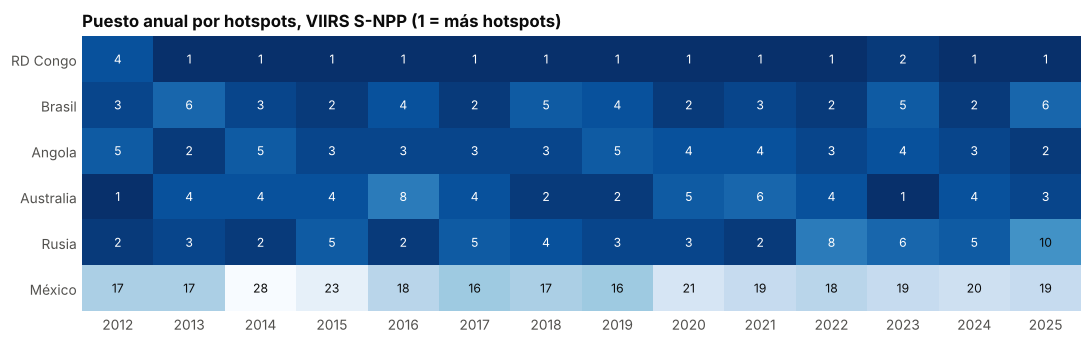

In [6]:
rows = []
ranks = {}
for inst in INSTR:
    a, b = FULL_YEARS[inst]
    d = cm[(cm.instrument == inst) & cm.year.between(a, b)].groupby(["year", "country"]).n.sum().reset_index()
    d["rank"] = d.groupby("year").n.rank(ascending=False, method="min")
    ranks[inst] = d
    for c in TARGET + [MEXICO]:
        r = d[d.country == c]["rank"]
        rows.append({"instrumento": NAMES[inst], "país": pretty(c), "años evaluados": b - a + 1,
                     "años en top-5": int((r <= 5).sum()), "años en top-10": int((r <= 10).sum()),
                     "mejor puesto": int(r.min()), "peor puesto": int(r.max())})
t5 = pd.DataFrame(rows)
short = {NAMES[k]: v for k, v in {"modis": "MODIS", "viirs-snpp": "S-NPP", "viirs-jpss1": "NOAA-20"}.items()}
t5["inst"] = t5["instrumento"].map(short)
t5["top-5"] = t5["años en top-5"].astype(str) + "/" + t5["años evaluados"].astype(str)
t5["rango de puestos"] = t5["mejor puesto"].astype(str) + "–" + t5["peor puesto"].astype(str)
view = (t5.pivot(index="país", columns="inst", values=["top-5", "rango de puestos"])
          .reindex([pretty(c) for c in TARGET + [MEXICO]]))
view = view.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)[["MODIS", "S-NPP", "NOAA-20"]]
display(view)
inside = t5[t5["país"].isin([pretty(c) for c in TARGET])]
print(f"Peor puesto anual de cualquiera de los 5 países: {int(inside['peor puesto'].max())}; "
      f"menor proporción de años en top-5: {(inside['años en top-5']/inside['años evaluados']).min():.0%}. México: mejor puesto anual {int(t5[t5['país']=='México']['mejor puesto'].min())}.")

# mapa de calor de puestos anuales, S-NPP
d = ranks["viirs-snpp"]
piv = d[d.country.isin(TARGET + [MEXICO])].pivot(index="country", columns="year", values="rank").loc[TARGET + [MEXICO]]
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(piv.values, cmap="Blues_r", vmin=1, vmax=25, aspect="auto")
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns)
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels([pretty(c) for c in piv.index])
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = int(piv.values[i, j]); ax.text(j, i, v, ha="center", va="center", fontsize=8,
                                           color="white" if v <= 8 else INK)
ax.set_title("Puesto anual por hotspots, VIIRS S-NPP (1 = más hotspots)")
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
plt.tight_layout(); plt.show()

Lectura honesta: la selección se sostiene en el **acumulado**, no en cada año. RD Congo y Angola están en el top-5 todos los años de S-NPP y NOAA-20, mientras que Brasil, Australia y Rusia entran la mayoría de los años pero no todos (Australia y Rusia tienen más variabilidad interanual, típica de años de sequía o incendios boreales extremos). Aun así, ninguno de los cinco cae fuera del top-10 en ningún año evaluado (ver la línea impresa). México no entra al top-5 en ningún año; su mejor puesto anual es el 11 (MODIS).

## 6. Concentración: ¿cuánto del total mundial concentran?

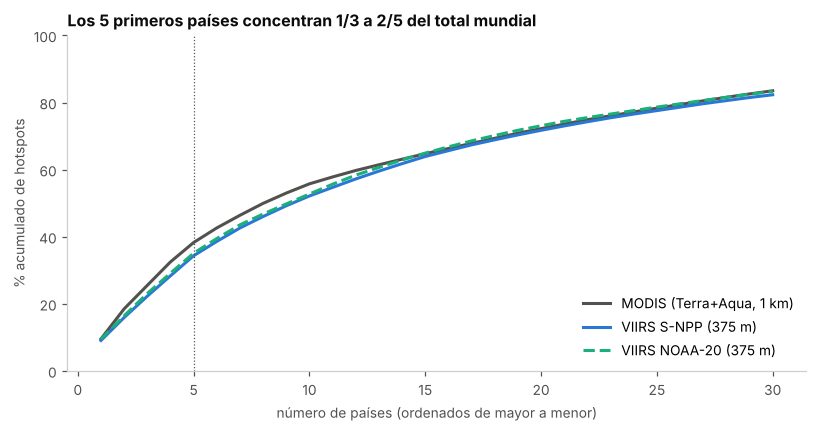

,instrumento,share top-5 (%),share top-10 (%),share México (%),puesto México,países con datos
0,"MODIS (Terra+Aqua, 1 km)",38.3,55.8,1.51,18,233
1,VIIRS S-NPP (375 m),34.3,52.1,1.50,18,236
2,VIIRS NOAA-20 (375 m),35.1,52.7,1.54,19,234


In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4))
rows = []
shades = {"modis": "#52514e", "viirs-snpp": C_TARGET, "viirs-jpss1": "#1baf7a"}
styles = {"modis": "-", "viirs-snpp": "-", "viirs-jpss1": "--"}
ax.set_ylim(0, 100)
for inst in INSTR:
    d = tot[tot.instrument == inst].sort_values("n", ascending=False)
    cum = d.n.cumsum() / d.n.sum()
    ax.plot(range(1, 31), cum.iloc[:30].values * 100, styles[inst], color=shades[inst], lw=2, label=NAMES[inst])
    rows.append({"instrumento": NAMES[inst], "share top-5 (%)": round(cum.iloc[4] * 100, 1),
                 "share top-10 (%)": round(cum.iloc[9] * 100, 1),
                 "share México (%)": round(d[d.country == MEXICO].share_n.iloc[0] * 100, 2),
                 "puesto México": int(d[d.country == MEXICO].rank_n.iloc[0]),
                 "países con datos": len(d)})
ax.axvline(5, color=INK2, lw=0.8, ls=":")
ax.set_xlabel("número de países (ordenados de mayor a menor)"); ax.set_ylabel("% acumulado de hotspots")
ax.set_title("Los 5 primeros países concentran 1/3 a 2/5 del total mundial", fontsize=10.5)
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()
display(pd.DataFrame(rows))

Entre ~235 países, cinco acumulan entre un tercio y dos quintos de todos los hotspots detectados. El porcentaje de México se muestra aparte: sirve para dimensionar cuánto del problema global representa el país, no para compararlo con los cinco.

## 7. Dónde ocurre: mapa global en celdas de 1° (VIIRS S-NPP, 2012–2025)

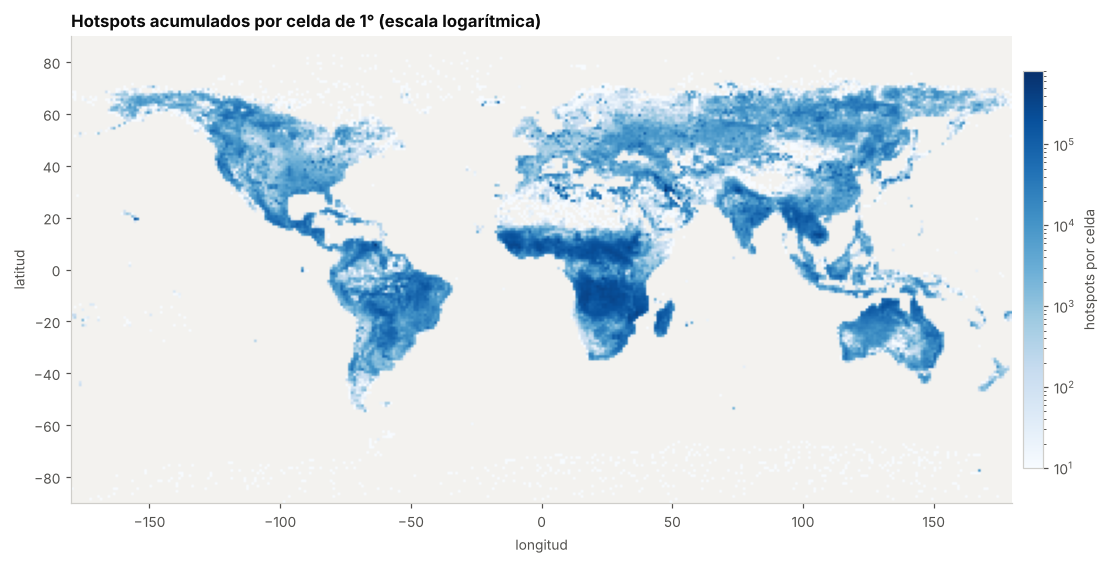

In [8]:
grid = pd.read_csv(DERIVED / "summary_grid1deg_year.csv.gz")
g = grid[grid.instrument == "viirs-snpp"].groupby(["lat_cell", "lon_cell"]).n.sum().reset_index()
M = np.zeros((180, 360))
M[(g.lat_cell + 90).clip(0, 179), (g.lon_cell + 180).clip(0, 359)] = g.n
M = np.ma.masked_equal(M, 0)
fig, ax = plt.subplots(figsize=(11, 5.2))
im = ax.imshow(M, origin="lower", extent=[-180, 180, -90, 90], cmap="Blues",
               norm=LogNorm(vmin=10, vmax=M.max()), aspect="auto")
ax.set_facecolor("#f3f2ef")
ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
ax.set_title("Hotspots acumulados por celda de 1° (escala logarítmica)")
cb = plt.colorbar(im, ax=ax, pad=0.01, shrink=0.85); cb.set_label("hotspots por celda")
plt.tight_layout(); plt.show()

El mapa no dibuja fronteras y usa escala logarítmica, así que sirve como contexto, no como prueba. Lo más nítido es el cinturón de sabana africano (RD Congo, Angola, Zambia, Mozambique), con los valores más altos. Brasil y el norte de Australia también destacan; Rusia se ve más difusa porque su fuego está disperso en una superficie enorme, lo que ayuda a explicar su cuenta alta pero no se aprecia bien aquí.

## 8. Tabla final de justificación

In [9]:
rows = []
for c in TARGET + [MEXICO]:
    r = {"país": pretty(c)}
    for inst in INSTR:
        d = tot[(tot.instrument == inst) & (tot.country == c)].iloc[0]
        short = {"modis": "MODIS", "viirs-snpp": "S-NPP", "viirs-jpss1": "NOAA-20"}[inst]
        r[f"puesto n {short}"] = d.rank_n
        r[f"puesto FRP {short}"] = d.rank_frp
    s = tot[(tot.instrument == "viirs-snpp") & (tot.country == c)].iloc[0]
    r["hotspots S-NPP (M)"] = round(s.n / 1e6, 2)
    r["share S-NPP (%)"] = round(s.share_n * 100, 1)
    yrs = t5[(t5["país"] == pretty(c)) & (t5["instrumento"] == NAMES["viirs-snpp"])].iloc[0]
    r["años top-5 S-NPP"] = f"{yrs['años en top-5']}/{yrs['años evaluados']}"
    rows.append(r)
final = pd.DataFrame(rows)
display(final)
out = DERIVED / "justificacion_paises.csv"
final.to_csv(out, index=False)
print("Guardado:", out)

ok3 = int(t3["coincide con los 5"].sum()); ok4 = int(t4["coincide"].sum())
print(f"\nResumen: el conjunto propuesto es el top-5 en {ok3}/{len(t3)} pruebas (todo el archivo) y en {ok4}/{len(t4)} (2019-2025).")

,país,puesto n MODIS,puesto FRP MODIS,puesto n S-NPP,puesto FRP S-NPP,puesto n NOAA-20,puesto FRP NOAA-20,hotspots S-NPP (M),share S-NPP (%),años top-5 S-NPP
0,RD Congo,1,3,1,1,1,1,25.50,9.1,14/14
1,Brasil,2,1,2,3,2,3,19.23,6.8,12/14
2,Angola,4,5,3,2,3,2,17.90,6.4,14/14
3,Australia,5,2,4,4,4,4,17.08,6.1,12/14
4,Rusia,3,4,5,5,5,5,16.80,6.0,11/14
5,México,18,19,18,19,19,20,4.23,1.5,0/14


Guardado: Data/analisis/01_paises/tablas/justificacion_paises.csv

Resumen: el conjunto propuesto es el top-5 en 6/6 pruebas (todo el archivo) y en 6/6 (2019-2025).


## 9. Conclusión y límites

**Conclusión.** Los cinco países propuestos son el top-5 del archivo FIRMS en los tres instrumentos, tanto por número de hotspots como por FRP acumulado, y también en el periodo común 2019–2025 (ver los conteos de pruebas aprobadas arriba). México queda fuera del top-5 (puestos ~18–19 por conteo) y se mantiene en el análisis como región de interés propia.

**Límites que conviene declarar al presentarlo**
- *Hotspots no son área quemada.* Cuentan detecciones de píxel; un incendio grande o persistente genera muchos. No se normalizó por superficie del país (no hay datos de área en las tablas): los países grandes tienen ventaja natural. Si se quiere "densidad de fuego", habrá que normalizar.
- *Sin filtro de `confidence`.* Las tablas incluyen todas las detecciones del CSV, también las de baja confianza. Habría que repetir el ranking con un umbral común para la armonización final.
- *Tipo de fuego.* Mucho del conteo en África y Brasil es quema agrícola o de sabana, no incendio forestal de emergencia. Para la audiencia de gestión de emergencias, la lista podría cambiar si se filtra por `type` (aún no verificado el significado de los códigos).
- *Instrumentos distintos.* Se comparó dentro de cada sensor; no se mezclaron conteos MODIS y VIIRS.
- *Asignación por país.* Se usa el país del archivo de FIRMS; no se verificó el tratamiento de hotspots en océano o frontera.
- *Alcance temporal.* El archivo llega a 2025; 2026 y NOAA-21 solo están por Area API.

**Siguiente paso.** Extraer los CSV completos de estos seis países (`python download_firms.py . --extract --countries Mexico Brazil Angola Australia Russian_Federation Democratic_Republic_of_the_Congo`) y comenzar la armonización MODIS–VIIRS con el solape S-NPP / NOAA-20.